# Práctica 2 - Titanic DataSet
## Resultados de aprendizaje

Al finalizar la práctica, será capaz de:
1. Distinguir los datos de un registro individual de la información que se obtiene al resumir varios registros. Por ejemplo, identificar la diferencia entre la clase del boleto de un pasajero y el total de pasajeros por clase.
2. Generar reportes descriptivos en Python a partir de un archivo CSV, agrupando registros y calculando conteos, totales y otras medidas de resumen.v
3. Verificar la consistencia de un reporte comparando sus subtotales con el total del archivo y documentando cómo se trataron los valores faltantes.
4. Interpretar los resultados y comunicar por escrito qué muestran sobre los pasajeros incluidos en el archivo.

## Introducción

En 1912, el personal encargado del embarque del Titanic utilizaba listas en papel para registrar a los pasajeros. En esta práctica, estudiaremos ese registro como un ejemplo de procesamiento manual de transacciones. Las listas cumplían una función operativa: dejar constancia de quiénes viajaban. El dataset reúne datos de los pasajeros, como su clase y puerto de embarque, e incorpora un dato conocido después del naufragio: si sobrevivieron.

## Diccionarios de datos
El archivo `titanic.csv` contiene **891 registros y 12 columnas**. Cada filla representa un pasajero.

| Columna | Tipo de dato | Descripción |
| --- | --- | --- |
| `PassangerId` | Identificador entero | Código único asignado a cada pasajero en el dataset. |
| `Survived` | Categoría binario | Resultado registrado después del naufrágio. `0` = falleció, `1` = sobrevivió. |
| `Pclass` | Categoría ordinaria | Clase del boleto. `1` = primera, `2` = segunda, `3` = tercera. |
| `Name` | Texto | Nombre del pasajero tal como aparece en el archivo. |
| `Sex` | Categoría | Sexo registrado. Los valores del archivo son `female` y `male`. |
| `Age` | Número | Edad en años. Puede incuir valores fraccionarios, por ejemplo, para bebés menores de un año. |
| `SibSp` | Conteo entero | Número de hermanos, hermanas y cónyugues del pasajero a bordo. |
| `Parch` | Conteo entero | Números de padres, madres, hijos e hijas del pasajero a bordo. |
| `Ticket` | Código de texto | Código del boleto. Puede incluir letras, números y signos, y repetirse en los registros de varios pasajeros. |
| `Fare` | Número decimal | Tarifa registrada en la fila del pasajero. |
| `Cabin` | Código de texto | Identificación de la cabina, cuando figura en el registro. |
| `Embarked` | Categoría | Puerto de embarque. `C` = Cherburgo, `Q` = Queenstown, `S` = Southampton.

## Preguntas de Interés
1. ¿Cuántos pasajeros hay en el dataset y cuántos PassengerId distintos aparecen? ¿Coinciden los dos resultados?

In [1]:
import pandas as pd

df_pasageros = pd.read_csv('titanic.csv', dtype = {'PassengerId':int})
dataSet = len(df_pasageros)

num_passangerID = df_pasageros['PassengerId'].nunique()

tabla1 = pd.DataFrame({
    "Num de pasajeros": [dataSet],
    "Num de ID distintos": [num_passangerID],
    "¿Coinciden?": [dataSet == num_passangerID]
})

display(tabla1)

,Num de pasajeros,Num de ID distintos,¿Coinciden?
0,891,891,True


**No existen datos nulos, por lo que no afecta a las operaciones**

2. ¿Cuántos pasajeros de cada clase aparecen en el archivo? ¿Qué clase tiene más pasajeros registrados?

In [2]:
primeraClase = 0
segundaClase = 0
terceraClase = 0

for clase in df_pasageros['Pclass']:
    if clase == 1:
        primeraClase += 1
    elif clase == 2:
        segundaClase += 1
    elif clase == 3:
        terceraClase += 1

def claseMay():
    if primeraClase > segundaClase and primeraClase > terceraClase:
        mensaje = "La clase con mayor número de pasajeros es la Primera clase"
    elif segundaClase > primeraClase and segundaClase > terceraClase:
        mensaje = "La clase con mayor número de pasajeros es la Segunda clase"
    elif terceraClase > primeraClase and terceraClase > segundaClase:
        mensaje = "La clase con mayor número de pasajeros es la Tercera clase"
    return mensaje

tabla2 = pd.DataFrame({
    "Clase": ["Primera", "Segunda", "Tercera"],
    "Pasajeros": [primeraClase, segundaClase, terceraClase]
})


In [3]:
display(tabla2)
claseMay()

,Clase,Pasajeros
0,Primera,216
1,Segunda,184
2,Tercera,491


'La clase con mayor número de pasajeros es la Tercera clase'

**No existen datos nulos, por lo que no afecta a las operaciones**

3. ¿Cuántos pasajeros embarcaron en cada puerto y cuántos tienen el puerto sin registrar?

In [17]:
puertoC = 0
puertoQ = 0
puertoS = 0
puertosNulos = 0

for puertos in df_pasageros['Embarked']:
    if puertos == "C":
        puertoC += 1
    elif puertos == "Q":
        puertoQ += 1
    elif puertos == "S":
        puertoS += 1
    elif pd.isna(puertos):
        puertosNulos += 1

tabla3 = pd.DataFrame({
    "Puertos": ["Cherburgo", "Queenstown", "Southampton"],
    "Embarques": [puertoC, puertoQ, puertoS]
})

display(tabla3)
print("Número de personas sin registros de embarque: ", puertosNulos)


,Puertos,Embarques
0,Cherburgo,168
1,Queenstown,77
2,Southampton,644


Número de personas sin registros de embarque:  2


**No existen datos nulos, por lo que no afecta a las operaciones**

4. ¿Cuál es la tarifa promedio, mínima y máxima registrada para cada clase?

In [5]:
tarifaPrimera = df_pasageros[df_pasageros['Pclass'] == 1]["Fare"]

tarifaSegunda = df_pasageros[df_pasageros['Pclass'] == 2]["Fare"]

tarifaTercera = df_pasageros[df_pasageros['Pclass'] == 3]["Fare"]


In [6]:
tabla4 = pd.DataFrame({
    "Clase": ["Primera", "Segunda", "Tercera"],
    "Promedio de las Tarifas": [tarifaPrimera.mean(), tarifaSegunda.mean(), tarifaTercera.mean()],
    "Tarifa máxima": [tarifaPrimera.max(), tarifaSegunda.max(), tarifaTercera.max()],
    "Tarifa mínima": [tarifaPrimera.min(), tarifaSegunda.min(), tarifaTercera.min()]
})

display(tabla4)

,Clase,Promedio de las Tarifas,Tarifa máxima,Tarifa mínima
0,Primera,84.154687,512.3292,0.0
1,Segunda,20.662183,73.5000,0.0
2,Tercera,13.675550,69.5500,0.0


**No existen datos nulos, por lo que no afecta a las operaciones**

5. ¿Cuántos pasajeros de cada clase embarcaron en cada puerto?

In [7]:
pasajerosPuerto1C = df_pasageros[(df_pasageros['Pclass'] == 1) & (df_pasageros["Embarked"] == "C")].shape[0]
pasajerosPuerto1Q = df_pasageros[(df_pasageros["Pclass"] == 1) & (df_pasageros["Embarked"] == "Q")].shape[0]
pasajerosPuerto1S = df_pasageros[(df_pasageros["Pclass"] == 1) & (df_pasageros["Embarked"] == "S")].shape[0]

pasajerosPuerto2C = df_pasageros[(df_pasageros['Pclass'] == 2) & (df_pasageros["Embarked"] == "C")].shape[0]
pasajerosPuerto2Q = df_pasageros[(df_pasageros["Pclass"] == 2) & (df_pasageros["Embarked"] == "Q")].shape[0]
pasajerosPuerto2S = df_pasageros[(df_pasageros["Pclass"] == 2) & (df_pasageros["Embarked"] == "S")].shape[0]

pasajerosPuerto3C = df_pasageros[(df_pasageros['Pclass'] == 3) & (df_pasageros["Embarked"] == "C")].shape[0]
pasajerosPuerto3Q = df_pasageros[(df_pasageros["Pclass"] == 3) & (df_pasageros["Embarked"] == "Q")].shape[0]
pasajerosPuerto3S = df_pasageros[(df_pasageros["Pclass"] == 3) & (df_pasageros["Embarked"] == "S")].shape[0]

tabla5 = pd.DataFrame({
    "Clase": ["Primera", "Segunda", "Tercera"],
    "Puerto Cherburgo": [pasajerosPuerto1C, pasajerosPuerto2C, pasajerosPuerto3C],
    "Puerto Queenstown": [pasajerosPuerto1Q, pasajerosPuerto2Q, pasajerosPuerto3Q],
    "Puerto Southampton": [pasajerosPuerto1S, pasajerosPuerto2S, pasajerosPuerto3S]
})

display(tabla5)

,Clase,Puerto Cherburgo,Puerto Queenstown,Puerto Southampton
0,Primera,85,2,127
1,Segunda,17,3,164
2,Tercera,66,72,353


**No existen datos nulos, por lo que no afecta a las operaciones**

6. ¿Cuántos pasajeros sobrevivieron y cuántos fallecieron en cada clase?

In [8]:
pasajerosSobrevivientes1S = df_pasageros[(df_pasageros['Pclass'] == 1) & (df_pasageros["Survived"] == 1)].shape[0]
pasajerosSobrevivientes1F = df_pasageros[(df_pasageros['Pclass'] == 1) & (df_pasageros["Survived"] == 0)].shape[0]
pasajerosSobrevivientes2S = df_pasageros[(df_pasageros["Pclass"] == 2) & (df_pasageros["Survived"] == 1)].shape[0]
pasajerosSobrevivientes2F = df_pasageros[(df_pasageros["Pclass"] == 2) & (df_pasageros["Survived"] == 0)].shape[0]
pasajerosSobrevivientes3S = df_pasageros[(df_pasageros["Pclass"] == 3) & (df_pasageros["Survived"] == 1)].shape[0]
pasajerosSobrevivientes3F = df_pasageros[(df_pasageros["Pclass"] == 3) & (df_pasageros["Survived"] == 0)].shape[0]

tabla6 = pd.DataFrame({
    "Clase": ["Primera", "Segunda", "Tercera"],
    "Sobrevivientes": [pasajerosSobrevivientes1S, pasajerosSobrevivientes2S, pasajerosSobrevivientes3S],
    "Fallecidos": [pasajerosSobrevivientes1F, pasajerosSobrevivientes2F, pasajerosSobrevivientes3F]
})

display(tabla6)

,Clase,Sobrevivientes,Fallecidos
0,Primera,136,80
1,Segunda,87,97
2,Tercera,119,372


**No existen datos nulos, por lo que no afecta a las operaciones**

7. ¿Cuántos pasajeros viajaban con cero, uno o dos o más familiares registrados a bordo?

In [16]:
pasajeros0F = df_pasageros[df_pasageros["SibSp"] + df_pasageros["Parch"] == 0].shape[0]
pasajeros1F = df_pasageros[df_pasageros["SibSp"] + df_pasageros["Parch"] == 1].shape[0]
pasajerosMasF = df_pasageros[df_pasageros["SibSp"] + df_pasageros["Parch"]  >= 2].shape[0]

tabla7 = pd.DataFrame({
    "Números de familiares": ["Cero familiares", "Un familiar", "Dos o más familiares"],
    "Cantidad": [pasajeros0F, pasajeros1F, pasajerosMasF],
})

display(tabla7)

,Números de familiares,Cantidad
0,Cero familiares,537
1,Un familiar,161
2,Dos o más familiares,193


**No existen datos nulos, por lo que no afecta a las operaciones**

8. ¿Cuántos pasajeros tenían menos de 18 años, cuántos tenían 18 o más y cuántos tenían la edad sin registrar? Desglose el resultado por clase.

In [18]:
primeraPasajerosMenores = df_pasageros[(df_pasageros["Age"] < 18) & (df_pasageros["Pclass"] == 1)].shape[0]
segundaPasajerosMenores = df_pasageros[(df_pasageros["Age"] < 18) & (df_pasageros["Pclass"] == 2)].shape[0]
terceraPasajerosMenores = df_pasageros[(df_pasageros["Age"] < 18) & (df_pasageros["Pclass"] == 3)].shape[0]


primeraPasajerosMayores = df_pasageros[(df_pasageros["Age"] >= 18) & (df_pasageros["Pclass"] == 1)]. shape[0]
segundaPasajerosMayores = df_pasageros[(df_pasageros["Age"] >= 18) & (df_pasageros["Pclass"] == 2)]. shape[0]
terceraPasajerosMayores = df_pasageros[(df_pasageros["Age"] >= 18) & (df_pasageros["Pclass"] == 3)]. shape[0]


primeraPasajerosSinRegistro = df_pasageros[(df_pasageros["Age"].isna()) & (df_pasageros["Pclass"] == 1)].shape[0]
segundaPasajerosSinRegistro = df_pasageros[(df_pasageros["Age"].isna()) & (df_pasageros["Pclass"] == 2)].shape[0]
terceraPasajerosSinRegistro = df_pasageros[(df_pasageros["Age"].isna()) & (df_pasageros["Pclass"] == 3)].shape[0]

tabla8 = pd.DataFrame({
    "Clase": ["Primera", "Segunda", "Tercera"],
    "Menores a 18": [primeraPasajerosMenores, segundaPasajerosMenores, terceraPasajerosMenores],
    "Mayores o igual a 18": [primeraPasajerosMayores, segundaPasajerosMayores, terceraPasajerosMayores],
    "Sin registro": [primeraPasajerosSinRegistro, segundaPasajerosSinRegistro, terceraPasajerosSinRegistro],
})

display(tabla8)

,Clase,Menores a 18,Mayores o igual a 18,Sin registro
0,Primera,12,174,30
1,Segunda,23,150,11
2,Tercera,78,277,136


**No afectan los cálculos los datos sin registro.**
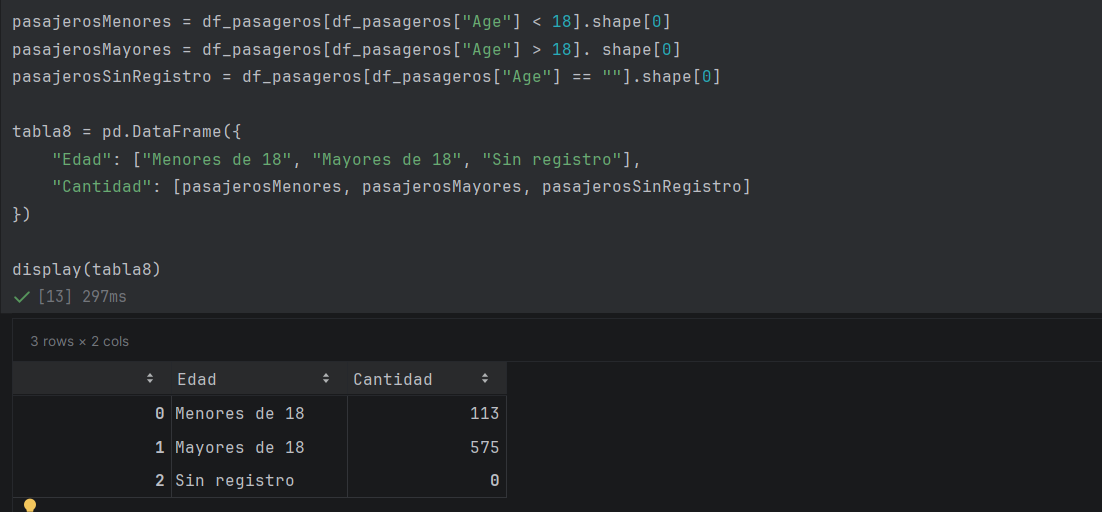

9. ¿Cuántos códigos de boleto distintos hay? ¿Cuántos aparecen asociados a más de un pasajero y cuál aparece en más registros?

In [24]:
ticketUnico = df_pasageros["Ticket"].nunique()
ticketAsociados = df_pasageros["Ticket"].value_counts()
cantidadRepetidos = ticketAsociados[ticketAsociados > 1].shape[0]

cantidadMaxima = ticketAsociados.max()
ticketsMasUsados = ticketAsociados[ticketAsociados == cantidadMaxima]


tabla9 = pd.DataFrame({
    "Tickets": ["Únicos", "Asociados a un pasajero", "Tickets más usados", "Cantidad de los tickets más usado"],
    "Cantidad": [ticketUnico, cantidadRepetidos, ", ".join(ticketsMasUsados.index.astype(str)), cantidadMaxima]
})

display(tabla9)

,Tickets,Cantidad
0,Únicos,681
1,Asociados a un pasajero,134
2,Tickets más usados,"347082, 1601, CA. 2343"
3,Cantidad de los tickets más usado,7


**No existen datos nulos, por lo que no afecta a las operaciones**

10. ¿En qué clase hay más registros sin cabina? Para cada clase, muestren cuántos registros tienen cabina, cuántos carecen de ella y cuántos hay en total.

In [15]:
primeraSinRegistros = df_pasageros[(df_pasageros["Pclass"] == 1) & (df_pasageros["Cabin"].isna())].shape[0]
segundaSinRegistros = df_pasageros[(df_pasageros["Pclass"] == 2) & (df_pasageros["Cabin"].isna())].shape[0]
terceraSinRegistros = df_pasageros[(df_pasageros["Pclass"] == 3) & (df_pasageros["Cabin"].isna())].shape[0]

primeraConRegistros = df_pasageros[(df_pasageros["Pclass"] == 1) & (df_pasageros["Cabin"].notna())].shape[0]
segundaConRegistros = df_pasageros[(df_pasageros["Pclass"] == 2) & (df_pasageros["Cabin"].notna())].shape[0]
terceraConRegistros = df_pasageros[(df_pasageros["Pclass"] == 3) & (df_pasageros["Cabin"].notna())].shape[0]

def masSinRegistros():
    if primeraSinRegistros > segundaSinRegistros and primeraSinRegistros > terceraSinRegistros:
        print("Primera clase con más registros sin cabina")
    elif segundaSinRegistros > primeraSinRegistros and segundaSinRegistros > terceraSinRegistros:
        print("Segunda clase con más registros sin cabina")
    elif terceraSinRegistros > segundaSinRegistros and terceraSinRegistros > primeraSinRegistros:
        print("Tercera clase con más registros sin cabina")

tabla10 = pd.DataFrame({
    "Clase": ["Primera", "Segunda", "Tercera"],
    "Sin Registros de cabina": [primeraSinRegistros, segundaSinRegistros, terceraSinRegistros],
    "Con registros de cabina": [primeraConRegistros, segundaConRegistros, terceraConRegistros],
    "Total de datos": [primeraConRegistros+primeraSinRegistros, segundaSinRegistros+segundaConRegistros, terceraConRegistros+terceraSinRegistros]
})


display(tabla10)
masSinRegistros()


,Clase,Sin Registros de cabina,Con registros de cabina,Total de datos
0,Primera,40,176,216
1,Segunda,168,16,184
2,Tercera,479,12,491


Tercera clase con más registros sin cabina


**No afectan los cálculos los datos sin registro.**